# HireSight — Recruitment EDA

**End-to-end exploratory analysis of a synthetic ATS dataset (8,000 applications, 3,512 candidates raw / 3,500 processed, 45 jobs, Jan–Dec 2026).**

Pipeline position: this notebook consumes the outputs of the earlier phases —
`scripts/generate_dataset.py` (raw data, seed 42) and `scripts/clean_data.py`
(processed data + audit log). Sections 2–5 verify the raw→processed journey;
sections 6–12 perform the exploratory analysis; section 13 exports
aggregates for the Power BI dashboard.

> **Integrity note:** all data is synthetic. The AI screening scores are simulated
> with deliberate overlap between outcome groups. Every association reported below
> is descriptive — it is not evidence of causation, model quality, or fairness.

## 1. Objective and dataset description

**Business objective:** give a recruitment team visibility into demand, sourcing
channel effectiveness, funnel conversion, time-to-hire, and offer outcomes.

**Analysis questions (PRD Section 6):**
1. Recruitment demand — volume by job, department, and month
2. Source effectiveness — volume, conversion, time-to-hire, cost per hire
3. Funnel efficiency — stage reach, conversion, drop-off, ageing
4. Outcomes — offers, acceptance, declines
5. AI screening — score distributions and descriptive association with outcomes

**Tables** (processed layer, `data/processed/`):

| Table | Grain | Rows |
|---|---|---|
| applications | one row per application (central fact) | 8,000 |
| candidates | one row per candidate | 3,500 |
| jobs | one row per job posting | 45 |
| recruitment_sources | one row per sourcing channel | 8 |
| screening_results | one row per screened application | 7,541 |
| application_stage_history | one row per stage event | 23,835 |
| offers | one row per issued offer | 869 |
| source_costs | one row per source per month | 84 |

## 2. Imports and configuration

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
RAW, PROC = ROOT / "data" / "raw", ROOT / "data" / "processed"

NAVY, PURPLE, GRAY, LIGHT = "#001F3F", "#5E2A84", "#7D7D7D", "#9F87C0"
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "font.size": 10, "axes.grid": True,
    "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold",
})
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.1.1 | numpy 2.5.5


## 3. Load raw CSV files

In [2]:
raw = {name: pd.read_csv(RAW / f"{name}.csv") for name in [
    "candidates", "jobs", "recruitment_sources", "applications",
    "screening_results", "application_stage_history", "offers", "source_costs"]}
for name, df in raw.items():
    print(f"{name:30s} {df.shape[0]:>7,} rows x {df.shape[1]} cols")

candidates                       3,512 rows x 5 cols
jobs                                45 rows x 10 cols
recruitment_sources                  7 rows x 3 cols
applications                     8,000 rows x 6 cols
screening_results                7,551 rows x 6 cols
application_stage_history       23,835 rows x 6 cols
offers                             869 rows x 6 cols
source_costs                        84 rows x 4 cols


## 4. Data overview: dimensions, types, nulls, duplicates

A compact overview of the RAW layer. The deliberate quality issues injected at
generation time (documented in `data/raw/generation_metadata.json`) should be
visible here — casing variants, missing values, out-of-range scores.

In [3]:
overview = []
for name, df in raw.items():
    overview.append({
        "table": name, "rows": len(df),
        "null_cells": int(df.isna().sum().sum()),
        "duplicate_pk_rows": int(df.iloc[:, 0].duplicated().sum()),
    })
pd.DataFrame(overview)

,table,rows,null_cells,duplicate_pk_rows
0,candidates,3512,281,0
1,jobs,45,16,0
2,recruitment_sources,7,0,0
3,applications,8000,15,0
4,screening_results,7551,0,0
5,application_stage_history,23835,8000,0
6,offers,869,70,0
7,source_costs,84,0,0


In [4]:
# Where exactly are the nulls in the raw layer?
nulls = []
for name, df in raw.items():
    for col in df.columns:
        n = int(df[col].isna().sum())
        if n:
            nulls.append({"table": name, "column": col, "null_rows": n,
                          "pct": round(100 * n / len(df), 2)})
pd.DataFrame(nulls)

,table,column,null_rows,pct
0,candidates,experience_years,176,5.01
1,candidates,highest_education,105,2.99
2,jobs,closed_date,16,35.56
3,applications,source_id,15,0.19
4,application_stage_history,stage_duration_hours,8000,33.56
5,offers,response_date,70,8.06


In [5]:
# Text quality: how many category cells deviate from canonical form?
def non_canonical(series):
    s = series.dropna().astype(str)
    return int((s != s.str.strip().str.title()).sum()) if len(s) else 0

checks = [
    ("candidates.candidate_city", non_canonical(raw["candidates"]["candidate_city"])),
    ("candidates.highest_education", non_canonical(raw["candidates"]["highest_education"])),
    ("stage_history.stage_name", int((raw["application_stage_history"]["stage_name"]
        != raw["application_stage_history"]["stage_name"].str.strip().str.lower()).sum())),
    ("screening.ai_score out of 0-100",
     int(((raw["screening_results"]["ai_score"] < 0) | (raw["screening_results"]["ai_score"] > 100)).sum())),
    ("applications missing source_id", int(raw["applications"]["source_id"].isna().sum())),
]
pd.DataFrame(checks, columns=["check", "rows_affected"])

,check,rows_affected
0,candidates.candidate_city,559
1,candidates.highest_education,3079
2,stage_history.stage_name,100
3,screening.ai_score out of 0-100,10
4,applications missing source_id,15


**Reading the checks:** the raw layer contains exactly the documented quality
issues — nulls in optional candidate fields, casing/whitespace corruption in
category fields, 15 missing sources, and 10 out-of-range scores. Nothing
unexpected appears, and no duplicate primary keys exist anywhere.

## 5. Cleaning and standardisation

The full cleaning logic lives in `scripts/clean_data.py`; its audit trail is
`data/processed/cleaning_log.md`. Summary of decisions:

| Issue | Decision |
|---|---|
| Casing/whitespace (≈300 cells) | standardised to canonical values |
| Missing source_id (15) | attributed to source 8 "Unknown / Not Recorded" |
| Out-of-range scores (10) | quarantined, never clipped or fabricated |
| Disordered stage timestamps (8) | repaired, durations recomputed |
| Near-duplicate candidates (12) | merged into originals |
| Missing experience/education | retained as NULL — imputing would fabricate data |

In [6]:
# Load the PROCESSED layer used for all analysis below
proc = {name: pd.read_csv(PROC / f"{name}.csv") for name in raw.keys()}
for name in ["applications", "candidates", "jobs", "screening_results",
             "application_stage_history", "offers", "source_costs"]:
    df = pd.read_csv(PROC / f"{name}.csv", parse_dates=True)
    proc[name] = df

apps = proc["applications"].copy()
apps["applied_at"] = pd.to_datetime(apps["applied_at"])
jobs = proc["jobs"].copy()
cands = proc["candidates"].copy()
sources = proc["recruitment_sources"].copy()
screen = proc["screening_results"].copy()
screen["screening_date"] = pd.to_datetime(screen["screening_date"])
stages = proc["application_stage_history"].copy()
stages["stage_timestamp"] = pd.to_datetime(stages["stage_timestamp"])
offers = proc["offers"].copy()
costs = proc["source_costs"].copy()
costs["month_start"] = pd.to_datetime(costs["month_start"])

apps = apps.astype({"candidate_id": int, "job_id": int, "source_id": int})

# Reconciliation: raw vs processed
recon = pd.DataFrame([
    {"table": n, "raw_rows": len(raw[n]), "processed_rows": len(proc[n]),
     "change": len(proc[n]) - len(raw[n])} for n in raw.keys()])
recon

,table,raw_rows,processed_rows,change
0,candidates,3512,3500,-12
1,jobs,45,45,0
2,recruitment_sources,7,8,1
3,applications,8000,8000,0
4,screening_results,7551,7541,-10
5,application_stage_history,23835,23835,0
6,offers,869,869,0
7,source_costs,84,84,0


## 6. Recruitment volume analysis

**Questions:** how many applications were received, which jobs/departments get
the most, and how does volume move month over month?

In [7]:
print("Total applications:      ", f"{len(apps):,}")
print("Unique applicants:       ", f"{apps['candidate_id'].nunique():,}")
print("Applications per applicant:", round(len(apps) / apps['candidate_id'].nunique(), 2))
print("Jobs applied to:         ", apps["job_id"].nunique(), "of", len(jobs))

dept = apps.merge(jobs[["job_id", "department"]], on="job_id")["department"].value_counts()
dept

Total applications:       8,000
Unique applicants:        3,500
Applications per applicant: 2.29
Jobs applied to:          45 of 45


department
Technology          2339
Sales               1805
Operations          1362
Customer Support    1178
Finance              709
Human Resources      607
Name: count, dtype: int64

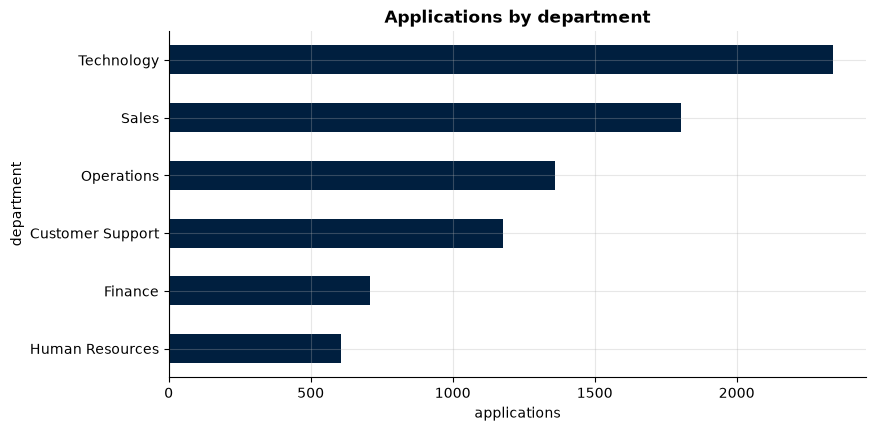

In [8]:
fig, ax = plt.subplots()
dept.plot.barh(ax=ax, color=NAVY)
ax.set_title("Applications by department")
ax.set_xlabel("applications")
ax.invert_yaxis()
plt.show()

In [9]:
# Top and bottom jobs by application volume
job_vol = (apps.merge(jobs[["job_id", "job_title", "department"]], on="job_id")
           .groupby(["job_title", "department"], as_index=False)
           .agg(applications=("application_id", "count")))
top = job_vol.nlargest(10, "applications")
bottom = job_vol.nsmallest(10, "applications")
print("TOP 10:"); display(top)
print("BOTTOM 10:"); display(bottom)

TOP 10:


,job_title,department,applications
33,Sales Executive,Sales,407
7,Data Analyst,Technology,356
17,Inside Sales Executive,Sales,334
37,Software Engineer,Technology,320
6,Customer Support Exec.,Customer Support,305
28,Process Associate,Operations,271
42,Technical Support Engineer,Customer Support,263
1,Backend Developer,Technology,262
14,Frontend Developer,Technology,251
2,Business Development Exec,Sales,248


BOTTOM 10:


,job_title,department,applications
32,Regional Sales Manager,Sales,53
12,Finance Manager,Finance,73
10,Engineering Manager,Technology,83
15,HR Business Partner,Human Resources,83
25,Ops Team Lead,Operations,94
18,Internal Auditor,Finance,96
36,Security Analyst,Technology,98
3,Channel Sales Manager,Sales,99
20,Key Account Manager,Sales,107
34,Sales Manager,Sales,108


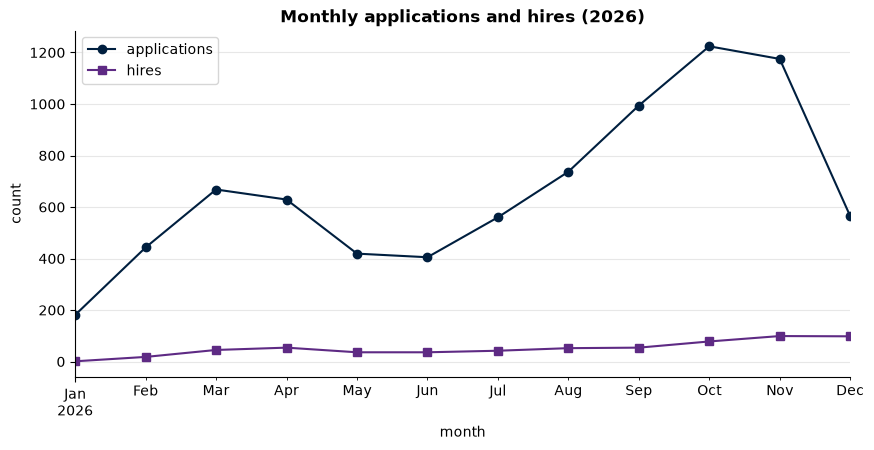

,applications,hires,app_MoM_change
month,,,
2026-01,181,1,NaN
2026-02,443,18,262.00
2026-03,668,45,225.00
2026-04,629,54,-39.00
2026-05,419,36,-210.00
2026-06,405,36,-14.00
2026-07,560,42,155.00
2026-08,737,52,177.00
2026-09,994,54,257.00


In [10]:
# Monthly trend: applications and hires
monthly = (apps.assign(month=apps["applied_at"].dt.to_period("M"))
           .groupby("month").size().rename("applications"))
hired_ts = (stages.loc[stages["stage_name"] == "hired", ["application_id", "stage_timestamp"]]
            .rename(columns={"stage_timestamp": "hired_at"}))
hires_monthly = (hired_ts.assign(month=hired_ts["hired_at"].dt.to_period("M"))
                 .groupby("month").size().rename("hires"))
trend = pd.concat([monthly, hires_monthly], axis=1).fillna(0).astype(int)
trend["app_MoM_change"] = trend["applications"].diff()

fig, ax = plt.subplots(figsize=(10, 4.5))
trend["applications"].plot(ax=ax, marker="o", color=NAVY, label="applications")
trend["hires"].plot(ax=ax, marker="s", color=PURPLE, label="hires", secondary_y=False)
ax.set_title("Monthly applications and hires (2026)")
ax.set_ylabel("count")
ax.legend()
plt.show()
trend

**Interpretation:** volume follows a hiring seasonality — stronger in
Q1 and the pre-festival autumn months, weaker mid-year and in December.
December's hire count falls steeply because applications late in the year are
still in process (they appear as active pipeline, not as losses).

## 7. Source effectiveness analysis

**Questions:** which sources generate volume, which convert to hires, how fast,
and what does a hire cost through each channel?

In [11]:
src = apps.merge(sources, on="source_id")
src_sum = (src.groupby(["source_name", "source_category"], as_index=False)
           .agg(applications=("application_id", "count")))
src_sum["hires"] = (src.groupby(["source_name", "source_category"])
                    ["current_status"].apply(lambda s: int((s == "hired").sum())).values)
src_sum["app_to_hire_pct"] = 100 * src_sum["hires"] / src_sum["applications"]
src_sum = src_sum.sort_values("applications", ascending=False)
src_sum

,source_name,source_category,applications,hires,app_to_hire_pct
3,Online Job Board,paid,2667,126,4.72
1,Company Careers Page,organic,1419,141,9.94
4,Recruitment Agency,agency,975,126,12.92
5,Social Media Ads,paid,956,26,2.72
2,Employee Referral,referral,815,135,16.56
0,Campus Hiring,organic,684,38,5.56
7,Walk-in / Job Fair,organic,469,20,4.26
6,Unknown / Not Recorded,unclassified,15,1,6.67


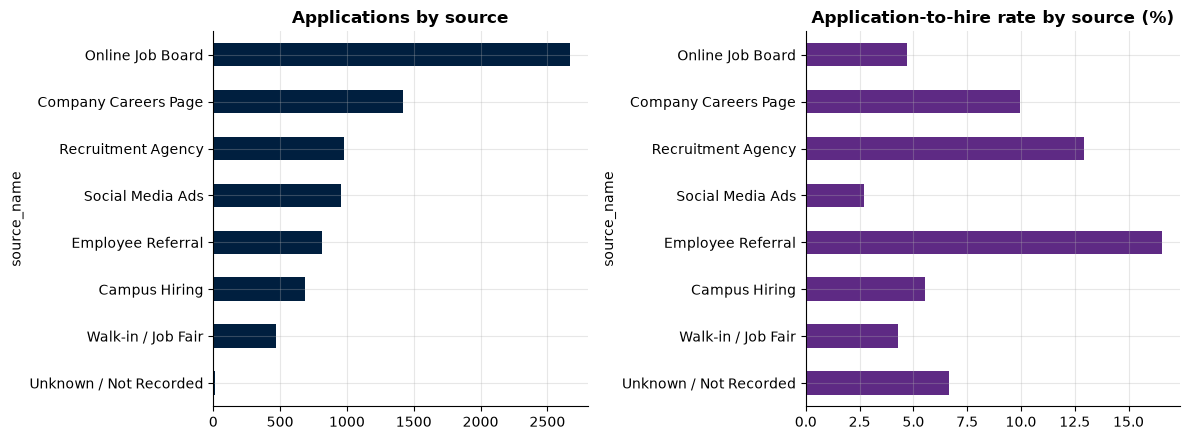

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
src_sum.plot.barh(x="source_name", y="applications", ax=axes[0], color=NAVY, legend=False)
axes[0].set_title("Applications by source")
axes[0].invert_yaxis()
src_sum.plot.barh(x="source_name", y="app_to_hire_pct", ax=axes[1], color=PURPLE, legend=False)
axes[1].set_title("Application-to-hire rate by source (%)")
axes[1].invert_yaxis()
plt.tight_layout()
plt.show()

**Interpretation:** volume and quality are different stories — the Online Job
Board dominates volume but converts poorly, while Employee Referral converts
several times better on far fewer applications. Read conversion together with
sample size: Walk-in/Job Fair percentages rest on a small base.

In [13]:
# Cost per hire: source spend in the calendar month of each hire / hires that month
# (attribution assumption documented in data/processed/cleaning_log.md)
cost_m = costs.assign(month=costs["month_start"].dt.month).groupby(["source_id", "month"])["cost_inr"].sum()
hires_by_src = (hired_ts.merge(apps[["application_id", "source_id"]], on="application_id")
                .assign(month=lambda d: d["hired_at"].dt.month)
                .groupby(["source_id", "month"]).size().rename("hires"))
cph = (pd.concat([cost_m.rename("cost_inr"), hires_by_src], axis=1).dropna()
       .assign(cost_per_hire=lambda d: d["cost_inr"] / d["hires"])
       .reset_index().merge(sources, on="source_id")
       .groupby(["source_name"], as_index=False)
       .agg(total_cost_inr=("cost_inr", "sum"), hires=("hires", "sum")))
cph["cost_per_hire_inr"] = cph["total_cost_inr"] / cph["hires"]
cph = cph.sort_values("cost_per_hire_inr")
cph

,source_name,total_cost_inr,hires,cost_per_hire_inr
2,Employee Referral,"193,695.65",135.00,"1,434.78"
1,Company Careers Page,"438,867.47",141.00,"3,112.54"
3,Online Job Board,"1,935,649.60",126.00,"15,362.30"
4,Recruitment Agency,"2,341,851.79",126.00,"18,586.13"
0,Campus Hiring,"1,066,498.30",38.00,"28,065.74"
6,Walk-in / Job Fair,"610,768.29",20.00,"30,538.41"
5,Social Media Ads,"1,093,610.83",26.00,"42,061.96"


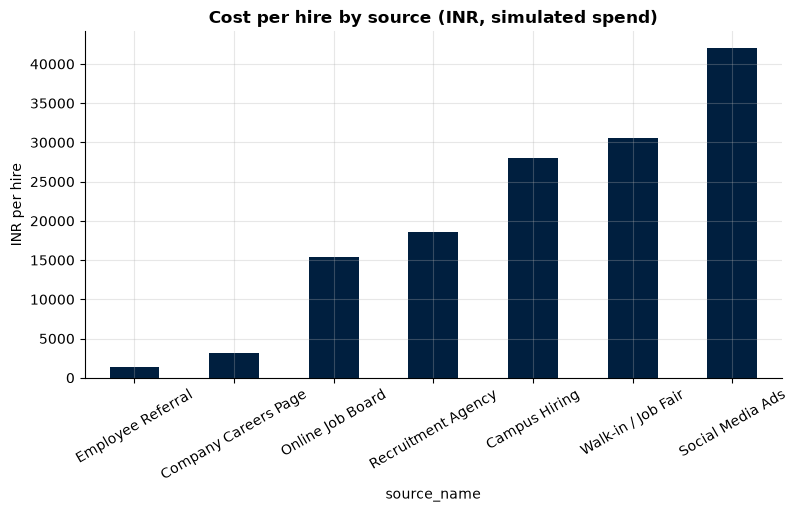

In [14]:
fig, ax = plt.subplots()
cph.plot.bar(x="source_name", y="cost_per_hire_inr", ax=ax, color=NAVY, legend=False)
ax.set_title("Cost per hire by source (INR, simulated spend)")
ax.set_ylabel("INR per hire")
ax.tick_params(axis="x", rotation=30)
plt.show()

**Interpretation:** referral hires are the cheapest (bonus payouts only);
the paid channels cost several times more per hire. Costs are simulated — the
value is the method (spend in hire month ÷ hires in that month), not the
absolute numbers.

## 8. Hiring funnel conversion analysis

**Questions:** how far do applications get, where is the largest drop-off, and
how many are still active?

Definitions: stage reach counts DISTINCT applications (stage history is
event-grain). Active statuses (screening/interview/offer) are never drop-offs.

In [15]:
order = ["applied", "screened", "interview", "offer", "hired"]
reach = stages.groupby("stage_name")["application_id"].nunique().reindex(order)
funnel = pd.DataFrame({"stage": order, "applications": reach.values})
funnel["stage_conversion_pct"] = 100 * funnel["applications"] / funnel["applications"].shift()
funnel["drop_off_from_prior"] = funnel["applications"].shift() - funnel["applications"]
funnel

,stage,applications,stage_conversion_pct,drop_off_from_prior
0,applied,8000,NaN,NaN
1,screened,7551,94.39,449.00
2,interview,3923,51.95,"3,628.00"
3,offer,869,22.15,"3,054.00"
4,hired,613,70.54,256.00


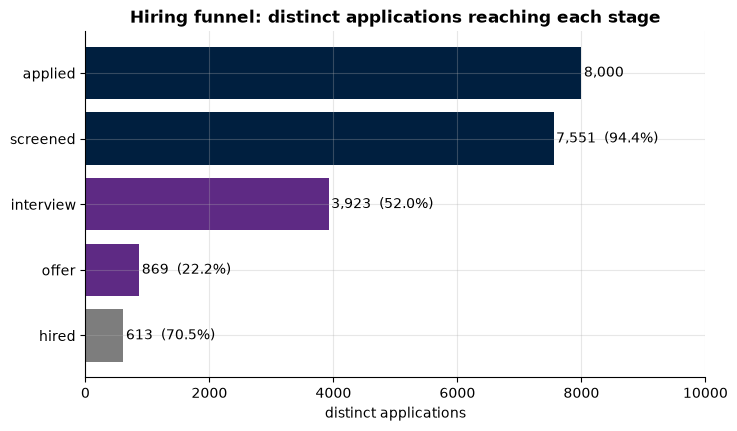

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(funnel["stage"], funnel["applications"], color=[NAVY, NAVY, PURPLE, PURPLE, GRAY])
for i, (n, pct) in enumerate(zip(funnel["applications"], funnel["stage_conversion_pct"])):
    ax.text(n + 40, i, f"{n:,}" + (f"  ({pct:.1f}%)" if pd.notna(pct) else ""), va="center")
ax.set_xlim(0, funnel["applications"].max() * 1.25)
ax.invert_yaxis()
ax.set_title("Hiring funnel: distinct applications reaching each stage")
ax.set_xlabel("distinct applications")
plt.show()

In [17]:
# Final outcomes and the still-active pipeline
outcomes = apps["current_status"].value_counts()
active = apps.loc[apps["current_status"].isin(["screening", "interview", "offer"]),
                  "current_status"].value_counts()
print(outcomes.to_string(), "\n")
print("Active (in process, NOT drop-offs):", int(active.sum()))

current_status
rejected     6209
withdrawn     712
hired         613
interview     226
declined      134
offer          70
screening      36 

Active (in process, NOT drop-offs): 332


**Interpretation:** the biggest absolute loss is at screening — most
applications never reach an interview, so screening capacity and precision is
the process bottleneck. The interview→offer step is the tightest percentage
gate after screening. A few hundred applications are still mid-funnel at
year end and must not be counted as failures.

## 9. Time-to-hire analysis

**Rule:** only hired applications count; days = applied_at → hired stage event.
Median is the headline (right-skewed distribution); the mean is shown for
comparison only.

In [18]:
fact = apps.merge(hired_ts, on="application_id", how="left")
fact["days_to_hire"] = (fact["hired_at"] - fact["applied_at"]).dt.total_seconds() / 86400
tth = fact.loc[fact["current_status"] == "hired", "days_to_hire"]

print(f"hires: {len(tth):,}")
print(f"mean:   {tth.mean():.1f} days")
print(f"median: {tth.median():.1f} days")
print(f"p25:    {tth.quantile(.25):.1f} days | p75: {tth.quantile(.75):.1f} days | p95: {tth.quantile(.95):.1f} days")
print(f"slowest single hire: {tth.max():.0f} days")

hires: 613
mean:   30.8 days
median: 28.6 days
p25:    22.3 days | p75: 36.8 days | p95: 52.3 days
slowest single hire: 87 days


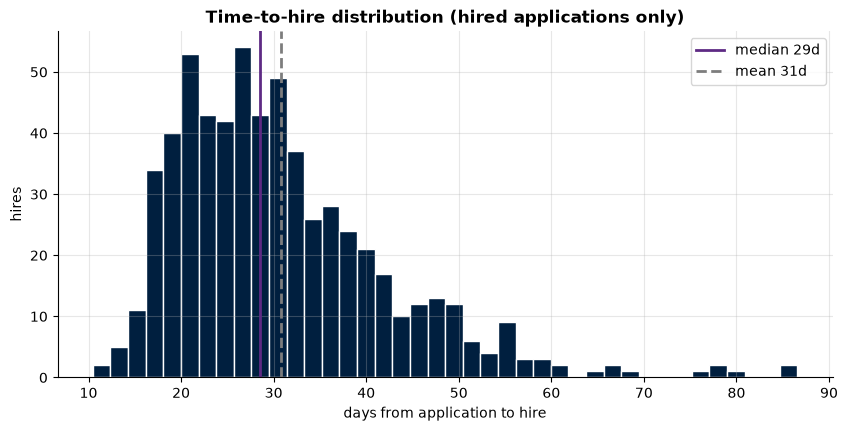

In [19]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(tth, bins=40, color=NAVY, edgecolor="white")
ax.axvline(tth.median(), color=PURPLE, lw=2, label=f"median {tth.median():.0f}d")
ax.axvline(tth.mean(), color=GRAY, lw=2, ls="--", label=f"mean {tth.mean():.0f}d")
ax.set_title("Time-to-hire distribution (hired applications only)")
ax.set_xlabel("days from application to hire")
ax.set_ylabel("hires")
ax.legend()
plt.show()

In [20]:
dept_tth = (fact.loc[fact["current_status"] == "hired"]
             .merge(jobs[["job_id", "department"]], on="job_id")
             .groupby("department")["days_to_hire"]
             .agg(median_days="median", mean_days="mean", hires="count")
             .sort_values("median_days"))
dept_tth

,median_days,mean_days,hires
department,,,
Customer Support,21.24,23.56,79
Sales,24.07,24.57,153
Operations,27.57,28.95,120
Human Resources,30.08,29.48,42
Technology,35.45,37.92,174
Finance,40.73,43.15,45


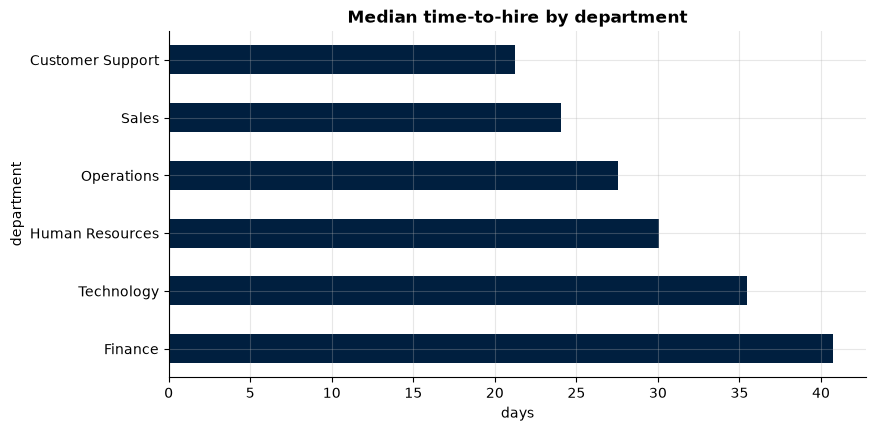

In [21]:
fig, ax = plt.subplots()
dept_tth["median_days"].plot.barh(ax=ax, color=NAVY)
ax.set_title("Median time-to-hire by department")
ax.set_xlabel("days")
ax.invert_yaxis()
plt.show()

**Interpretation:** the mean sits above the median and the p95 stretches far
beyond both — a classic right-skewed duration distribution, which is why the
median is the reported headline. Finance and Technology are slowest
(verification-heavy roles); Customer Support and Sales close fastest.

## 10. Offer outcomes

**Definitions:** acceptance rate = accepted ÷ decided offers (pending offers
excluded from the denominator).

In [22]:
offer_sum = offers["offer_status"].value_counts().rename("offers").to_frame()
decided = offer_sum.loc[offer_sum.index != "pending", "offers"].sum()
accepted = offer_sum.loc["accepted", "offers"] if "accepted" in offer_sum.index else 0
print(f"acceptance rate: {100 * accepted / decided:.1f}% "
      f"({accepted:,} accepted / {decided:,} decided)")

sal = offers.loc[offers["offer_status"] == "accepted", "offered_salary_inr"]
print(f"accepted offer salary: median {sal.median():,.0f} INR | range "
      f"{sal.min():,.0f} - {sal.max():,.0f} INR")
offer_sum

acceptance rate: 76.7% (613 accepted / 799 decided)
accepted offer salary: median 619,000 INR | range 272,000 - 3,127,000 INR


,offers
offer_status,
accepted,613
declined,134
pending,70
withdrawn,52


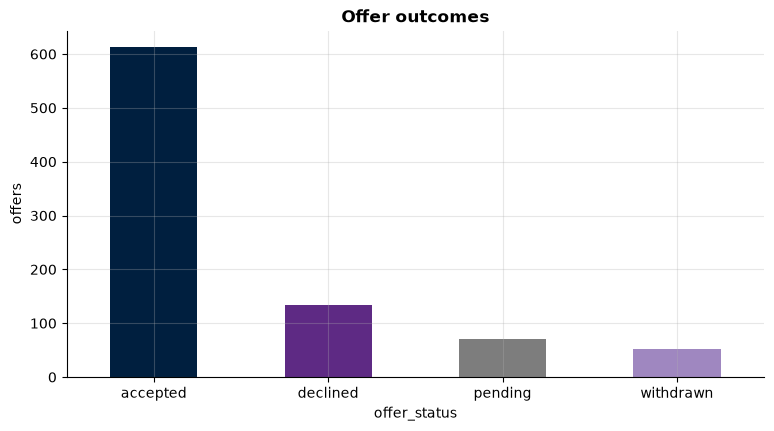

In [23]:
fig, ax = plt.subplots()
offer_sum["offers"].plot.bar(ax=ax, color=[NAVY, PURPLE, GRAY, LIGHT][:len(offer_sum)])
ax.set_title("Offer outcomes")
ax.set_ylabel("offers")
ax.tick_params(axis="x", rotation=0)
plt.show()

**Interpretation:** roughly three of four decided offers are accepted.
Declines and withdrawals are the visible 'loss at the last step' — each
represents a full funnel of effort spent without a hire, so they are worth
tracking alongside salary positioning.

## 11. AI screening score analysis

> **Descriptive only.** Scores are simulated with deliberate overlap between
> outcome groups. Nothing here establishes causation, predictive validity, or
> fairness — and a score band is never a 'good/bad candidate' label.

In [24]:
sc = fact.merge(screen[["application_id", "ai_score", "screening_decision"]], on="application_id")
print("scores:", f"{sc['ai_score'].notna().sum():,} (quarantined rows already excluded)")
print("mean", round(sc['ai_score'].mean(), 1), "| median", round(sc['ai_score'].median(), 1),
      "| sd", round(sc['ai_score'].std(), 1))
sc["ai_score"].describe()

scores: 7,541 (quarantined rows already excluded)
mean 57.7 | median 57.9 | sd 15.8


count   7,541.00
mean       57.69
std        15.82
min         4.79
25%        46.53
50%        57.90
75%        68.99
max       100.00
Name: ai_score, dtype: float64

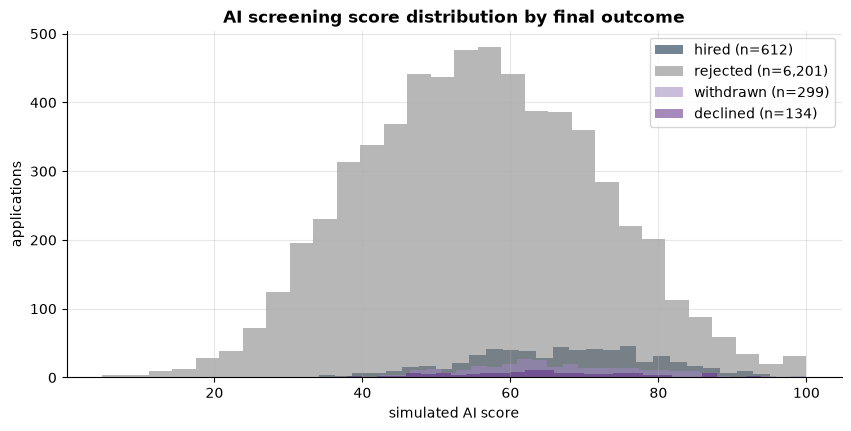

In [25]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for status, color in [("hired", NAVY), ("rejected", GRAY), ("withdrawn", LIGHT), ("declined", PURPLE)]:
    sub = sc.loc[sc["current_status"] == status, "ai_score"].dropna()
    if len(sub):
        ax.hist(sub, bins=30, alpha=0.55, label=f"{status} (n={len(sub):,})", color=color)
ax.set_title("AI screening score distribution by final outcome")
ax.set_xlabel("simulated AI score")
ax.set_ylabel("applications")
ax.legend()
plt.show()

In [26]:
# Score bands vs funnel progression (descriptive association)
sc["score_band"] = pd.cut(sc["ai_score"], bins=[0, 40, 60, 80, 100], include_lowest=True)
stages_reach = stages.pivot_table(index="application_id", columns="stage_name",
                                  values="stage_event_id", aggfunc="count").notna()
sc = sc.merge(stages_reach[["interview", "offer", "hired"]].rename(
    columns={"interview": "reached_interview", "offer": "reached_offer"}),
    on="application_id", how="left")
sc["hired_flag"] = sc["current_status"] == "hired"

band = (sc.groupby("score_band", observed=False)
        .agg(screened=("application_id", "count"),
             interview_rate=("reached_interview", "mean"),
             offer_rate=("reached_offer", "mean"),
             hire_rate=("hired_flag", "mean")))
band_pct = (band[["interview_rate", "offer_rate", "hire_rate"]] * 100).round(1)
pd.concat([band["screened"], band_pct], axis=1)

,screened,interview_rate,offer_rate,hire_rate
score_band,,,,
"(-0.001, 40.0]",1091,6.70,1.60,1.10
"(40.0, 60.0]",3052,36.10,8.40,5.60
"(60.0, 80.0]",2817,78.20,16.70,11.90
"(80.0, 100.0]",581,93.50,21.50,16.00


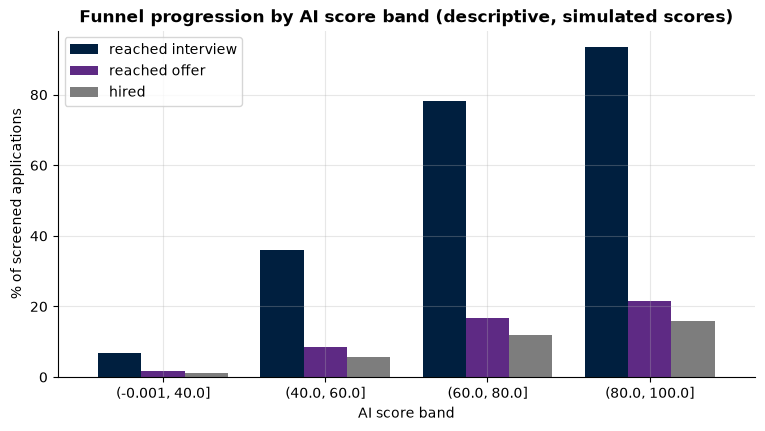

In [27]:
fig, ax = plt.subplots()
band_pct.plot.bar(ax=ax, color=[NAVY, PURPLE, GRAY], width=0.8)
ax.set_title("Funnel progression by AI score band (descriptive, simulated scores)")
ax.set_ylabel("% of screened applications")
ax.set_xlabel("AI score band")
ax.tick_params(axis="x", rotation=0)
ax.legend(["reached interview", "reached offer", "hired"])
plt.show()

In [28]:
# The overlap story: score is far from decisive
hi_not_hired = int(((sc["ai_score"] >= 75) & (sc["current_status"] != "hired")).sum())
lo_hired = int(((sc["ai_score"] < 50) & (sc["current_status"] == "hired")).sum())
print(f"high-score (>=75) NOT hired: {hi_not_hired:,}")
print(f"low-score  (<50)  hired:     {lo_hired:,}")

corr_int = sc["ai_score"].corr(sc["reached_interview"].astype(float))
corr_hire = sc["ai_score"].corr(sc["hired_flag"].astype(float))
print(f"Pearson r, score vs reached-interview: {corr_int:.2f}")
print(f"Pearson r, score vs hired:              {corr_hire:.2f}")
print("Correlation measures linear co-movement in SIMULATED data; it says nothing")
print("about causation, model quality, or fairness.")

high-score (>=75) NOT hired: 919
low-score  (<50)  hired:     60
Pearson r, score vs reached-interview: 0.58
Pearson r, score vs hired:              0.17
Correlation measures linear co-movement in SIMULATED data; it says nothing
about causation, model quality, or fairness.


**Interpretation:** progression rates rise with score band, but the
distributions overlap heavily — hundreds of high-score candidates are not
hired and dozens of low-score candidates are. A moderate positive Pearson r
quantifies co-movement only. These are exactly the properties the generator
was designed to exhibit, and they are the honest story for stakeholders.

## 12. Summary of findings and limitations

**Findings (evidence in sections 6–11):**
1. Demand concentrates in a few high-volume roles; volume is seasonal, peaking in Q1 and autumn.
2. Referrals convert several times better than paid job boards on a fraction of the volume — the clearest channel-quality gap in the data.
3. Screening is the largest funnel drop-off; most applications never reach an interview.
4. Time-to-hire is right-skewed: the median (~28 days) is the honest headline; the mean overstates the typical experience.
5. Departments differ systematically in speed (Finance/Technology slowest; Customer Support/Sales fastest) — consistent with role complexity, not recruiter effort.
6. Offer acceptance is ~77% of decided offers; declines are the costliest losses because they occur after the full funnel investment.
7. AI scores associate with progression but with heavy overlap (hundreds of high-score non-hires) — score is one signal among many, not a decision rule.

**Limitations:**
- All data is synthetic (seed 42); numbers demonstrate methodology, not real performance.
- Cost per hire uses a simplified calendar-month attribution assumption.
- Applications from December are truncated mid-funnel by the period boundary — cohort-based rates would be the more rigorous treatment.
- Score/outcome association is descriptive by construction; no causal, validity, or fairness claim is possible.
- Small-channel conversion rates (e.g. Walk-in/Job Fair) rest on small samples.

## 13. Export analysis-ready aggregates for Power BI

Star-schema-friendly outputs written to `data/processed/pbi/`. The Power BI
report (Phase 6) reads these files, keeping it portable and refreshable.

In [29]:
from pathlib import Path as _P
PBI = PROC / "pbi"
PBI.mkdir(parents=True, exist_ok=True)

# 1) application-level fact table
fact_pbi = (apps
    .merge(jobs[["job_id", "job_title", "department", "location", "employment_type",
                 "salary_min_inr", "salary_max_inr"]], on="job_id")
    .merge(sources, on="source_id")
    .merge(screen[["application_id", "ai_score", "screening_decision", "score_version"]],
           on="application_id", how="left")
    .merge(offers[["application_id", "offer_status", "offered_salary_inr",
                   "offer_date", "response_date"]], on="application_id", how="left")
    .merge(hired_ts, on="application_id", how="left"))
fact_pbi["days_to_hire"] = (fact_pbi["hired_at"] - fact_pbi["applied_at"]).dt.days
fact_pbi["is_hired"] = (fact_pbi["current_status"] == "hired").astype(int)
fact_pbi["is_active"] = fact_pbi["current_status"].isin(
    ["screening", "interview", "offer"]).astype(int)
for col in ["applied_at", "hired_at"]:
    fact_pbi[col] = pd.to_datetime(fact_pbi[col]).dt.date
fact_pbi.to_csv(PBI / "fact_applications.csv", index=False)

# 2) calendar dimension (2026)
cal = pd.DataFrame({"date": pd.date_range("2026-01-01", "2026-12-31", freq="D")})
cal["year"] = cal["date"].dt.year
cal["month"] = cal["date"].dt.month
cal["month_name"] = cal["date"].dt.strftime("%b")
cal["quarter"] = cal["date"].dt.quarter
cal["week_of_year"] = cal["date"].dt.isocalendar().week.astype(int)
cal["is_weekend"] = cal["date"].dt.dayofweek >= 5
cal["date"] = cal["date"].dt.date
cal.to_csv(PBI / "dim_calendar.csv", index=False)

# 3) funnel summary
funnel.to_csv(PBI / "funnel_summary.csv", index=False)

# 4) source summary with costs
src_pbi = (src_sum.merge(
    cph[["source_name", "total_cost_inr", "cost_per_hire_inr"]], on="source_name", how="left"))
src_pbi.to_csv(PBI / "source_summary.csv", index=False)

# 5) monthly trend
trend.reset_index().rename(columns={"index": "month"}).to_csv(
    PBI / "monthly_trend.csv", index=False)

# 6) department summary
dept_pbi = (fact.loc[fact["current_status"] == "hired"]
            .merge(jobs[["job_id", "department"]], on="job_id")
            .groupby("department", as_index=False)
            .agg(hires=("application_id", "count"),
                 median_days_to_hire=("days_to_hire", "median")))
dept_apps = apps.merge(jobs[["job_id", "department"]], on="job_id")["department"].value_counts()
dept_pbi["applications"] = dept_pbi["department"].map(dept_apps).astype(int)
dept_pbi.to_csv(PBI / "department_summary.csv", index=False)

# 7) score band summary
band_out = pd.concat([band["screened"], band_pct], axis=1).reset_index()
band_out["score_band"] = band_out["score_band"].astype(str)
band_out.to_csv(PBI / "score_band_summary.csv", index=False)

print("Exported to data/processed/pbi/:")
for f in sorted(PBI.glob("*.csv")):
    print(f"  {f.name:28s} {sum(1 for _ in open(f, encoding='utf-8')) - 1:>7,} rows")

Exported to data/processed/pbi/:
  department_summary.csv             6 rows
  dim_calendar.csv                 365 rows
  fact_applications.csv          8,000 rows
  funnel_summary.csv                 5 rows
  monthly_trend.csv                 12 rows
  score_band_summary.csv             4 rows
  source_summary.csv                 8 rows


C:\Users\aswin\AppData\Local\Temp\ipykernel_19532\2035205100.py:30: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  cal["is_weekend"] = cal["date"].dt.dayofweek >= 5


---
*Notebook ends. Dashboard build (Phase 6) consumes `data/processed/pbi/`; the
insights report (Phase 7) builds on sections 6–12. Every metric above reconciles
with the validated SQL in `database/queries/`.*